# Lesson 01: Context and experiment design

**Goal:** write the experiment plan *before* looking at any results.

This notebook deliberately never reads the outcome columns (`visit`, `conversion`, `spend`). Everything in it could have been written the week before the email was sent. That is the point: if you pick your metrics and decision rules after seeing the data, you can almost always find *something* that "worked". Writing the plan first is called **pre-registration**.

By the end you will have:

1. the business decision this experiment informs,
2. a metric tree and a role for every metric,
3. the hypotheses and how many comparisons we make,
4. a power analysis: what this experiment can and cannot detect,
5. decision rules written down in advance.

The final plan is saved in `reports/pre_registration.md`.

## 1. The business decision

**The company:** a US multichannel apparel retailer (2008) selling men's and women's merchandise through a website and a phone order line for catalogue customers.

**The stakeholder's question:** *"These are recent customers. Many of them would buy anyway. Does the email add anything?"*

That question can only be answered against a **holdout**: a randomly chosen group that receives nothing. Counting all purchases by people who got the email would credit the campaign with sales it did not cause.

**Decisions this experiment informs:**

| Decision | What we need to know |
|---|---|
| Keep sending these campaigns? | Does each email cause extra purchases and revenue over the holdout? |
| Which creative? | Does the men's or the women's email produce more incremental value? |
| Who should receive it? | Which customers respond, and which would buy anyway (lesson 06)? |

## 2. Design facts (known before the send)

| Item | Value |
|---|---|
| Unit of randomisation | Customer |
| Population | 64,000 customers who purchased in the last 12 months |
| Assignment | Random: one third to each arm |
| Arms | No e-mail (control), Men's e-mail, Women's e-mail |
| Treatment | One campaign email |
| Observation window | Two weeks after the send |
| Unit of analysis | Customer, the same as the unit of randomisation, so standard errors need no clustering |

## 3. The metric tree

The business cares about revenue. For one customer over the two-week window:

```
spend per customer = conversion rate × spend per buyer
                   = visit rate × P(purchase | visit) × spend per buyer
```

The tree tells us **where the email can act**. An email mainly works on the first link: it brings people back to the site. What happens after they arrive depends on the website, the products and the prices, which the email barely touches. So we expect the effect to be clearest on visits, diluted on purchases, and most diluted on spend.

(The second line assumes every purchase starts with a website visit. Phone orders from the catalogue could break that. Lesson 02 checks it in the data.)

> **A trap to remember:** `P(purchase | visit)` and `spend per buyer` are computed only for customers who visited or bought. The email changes *who* visits and buys, so comparing these between arms is no longer a randomised comparison. We use them to explain results, never to decide. Lesson 04 shows why.

## 4. Choosing metric roles

Every metric sits on a trade-off between two properties:

| Metric | Closeness to money | Sensitivity (how easily a real effect shows) |
|---|---|---|
| Visit rate | Low | High: common event, roughly 1 in 10 customers |
| Conversion rate | Medium | Medium: rare event, under 1 in 100 |
| Spend per customer | High | Low: almost everyone spends zero, and buyers vary hugely |

Rather than pick one and ignore the rest, each metric gets a **role**, decided now:

- **Primary metric:** the one metric the decision rests on. There is exactly one, because every extra decision metric raises the chance of a false positive. We size the experiment for it.
- **Secondary metrics:** expected to move; they explain *why* the primary moved.
- **Guardrail metrics:** must not get worse.
- **Validity checks:** tell us whether the experiment itself can be trusted.

### Draft choice (to discuss)

| Role | Metric | Reason |
|---|---|---|
| **Primary** | Conversion rate (purchase within 2 weeks) | The first link that proves money moved. A catchy subject line can inflate visits without sales; it cannot fake purchases. |
| Secondary | Visit rate | The mechanism: did the email bring people back? |
| Secondary | Spend per customer | The value, but weakly powered (section 7). |
| Descriptive only | P(purchase \| visit), spend per buyer | Explain the result; not randomised comparisons. |
| Guardrail (wanted, **not in the data**) | Unsubscribes, spam complaints, returns | Recorded as a limitation. |
| Validity | Sample-ratio mismatch, covariate balance | Checked in lesson 02, before reading outcomes. |

Visit rate as the primary metric is also defensible: it is what the email directly controls and it has the most statistical power. Spend as primary is closest to money but, as section 7 shows, this experiment is too small to measure it precisely. **Change the draft if you disagree, then rerun the notebook.**

## 5. Hypotheses and comparisons

**Confirmatory comparisons** on the primary metric:

- H1: the men's e-mail changes the conversion rate compared with no e-mail.
- H2: the women's e-mail changes the conversion rate compared with no e-mail.

Both tests are two-sided. Making two comparisons raises the chance that at least one is a false positive, so we control the **family-wise error rate at 5%** with the Holm correction.

For planning we use the simpler Bonferroni split, α = 0.05 / 2 = 0.025 per comparison. Holm is never less powerful than Bonferroni, so planning with Bonferroni is slightly conservative.

Men's vs women's is **secondary**: reported with a confidence interval, not used for a confirmatory claim.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from expt.power import mde_mean, mde_proportion, sample_size_proportions, zero_inflated_sd

N_TOTAL = 64_000
N_PER_ARM = N_TOTAL // 3          # 21,333 customers per arm
ALPHA_FAMILY = 0.05
N_CONFIRMATORY = 2                # men's vs control, women's vs control
ALPHA = ALPHA_FAMILY / N_CONFIRMATORY
POWER = 0.80

print(f"Customers per arm: {N_PER_ARM:,}")
print(f"Alpha per comparison: {ALPHA}  |  power: {POWER:.0%}")

Customers per arm: 21,333
Alpha per comparison: 0.025  |  power: 80%


## 6. Planning assumptions

A power analysis needs baseline values: how often do customers visit and buy *without* an email? In a real company these come from history, for example the holdouts of the last few campaigns. We have no history, and we must not peek at this experiment's control group. So we write explicit assumptions and then test how sensitive the conclusions are to them.

| Assumption | Value | Reasoning |
|---|---|---|
| Visit rate without email (2 weeks) | 10% | Recent customers return on their own fairly often |
| Conversion rate without email | 0.5% | Buying in any given two weeks is rare |
| Average order value | $100 | A typical apparel order |
| SD of order value | $90 | Orders vary almost as much as their average |

In [2]:
assumptions = {
    "visit_rate": 0.10,
    "conversion_rate": 0.005,
    "order_mean": 100.0,
    "order_sd": 90.0,
}

### Spend per customer is zero-inflated

Spend is zero for about 99.5% of customers and an order value for the rest. Its standard deviation follows from the assumptions above:

$$\text{Var(spend)} = p\,(\sigma_{order}^2 + \mu_{order}^2) - (p\,\mu_{order})^2$$

where $p$ is the conversion rate. The mean is tiny but the SD is large, which is exactly what makes revenue hard to test.

In [3]:
p = assumptions["conversion_rate"]
spend_mean = p * assumptions["order_mean"]
spend_sd = zero_inflated_sd(p, assumptions["order_mean"], assumptions["order_sd"])

print(f"Planned spend per customer: mean ${spend_mean:.2f}, SD ${spend_sd:.2f}")
print(f"The SD is {spend_sd / spend_mean:.0f}x the mean")

Planned spend per customer: mean $0.50, SD $9.50
The SD is 19x the mean


## 7. What can this experiment detect?

The **minimum detectable effect (MDE)** is the smallest true lift the experiment would detect 80% of the time. Effects smaller than the MDE may well exist, but this experiment would usually miss them.

In [4]:
mde_visit = mde_proportion(assumptions["visit_rate"], N_PER_ARM, N_PER_ARM, ALPHA, POWER)
mde_conv = mde_proportion(assumptions["conversion_rate"], N_PER_ARM, N_PER_ARM, ALPHA, POWER)
mde_spend = mde_mean(spend_sd, N_PER_ARM, N_PER_ARM, ALPHA, POWER)

mde_table = pd.DataFrame(
    {
        "baseline": [assumptions["visit_rate"], assumptions["conversion_rate"], spend_mean],
        "MDE (absolute)": [mde_visit, mde_conv, mde_spend],
    },
    index=["Visit rate", "Conversion rate", "Spend per customer ($)"],
)
mde_table["MDE (relative)"] = mde_table["MDE (absolute)"] / mde_table["baseline"]
mde_table.style.format(
    {"baseline": "{:.4f}", "MDE (absolute)": "{:.4f}", "MDE (relative)": "{:.0%}"}
)

,baseline,MDE (absolute),MDE (relative)
Visit rate,0.1000,0.0091,9%
Conversion rate,0.0050,0.0023,47%
Spend per customer ($),0.5000,0.2836,57%


**How to read this:**

- **Visit rate:** the experiment can detect a lift of roughly 9%, for example 10% → 10.9%. Comfortable.
- **Conversion rate:** it needs a lift of roughly 47%, for example 0.5% → 0.73%. One email lifting purchases that much in two weeks is ambitious. If the true lift is 20%, this experiment will probably miss it.
- **Spend per customer:** it needs roughly 57% more revenue per customer. Revenue is the weakest-powered metric, despite being the one the business cares about most.

So choosing conversion as the primary metric is a real trade-off: it is closer to money than visits, but the experiment is only powered for a large effect on it. Writing this down now matters. If conversion turns out not significant, we will know whether that means "no effect" or "effect too small for this experiment to see".

## 8. How many customers would we need?

The same calculation in reverse: customers per arm needed to detect a given relative lift. The dashed line is what this experiment has.

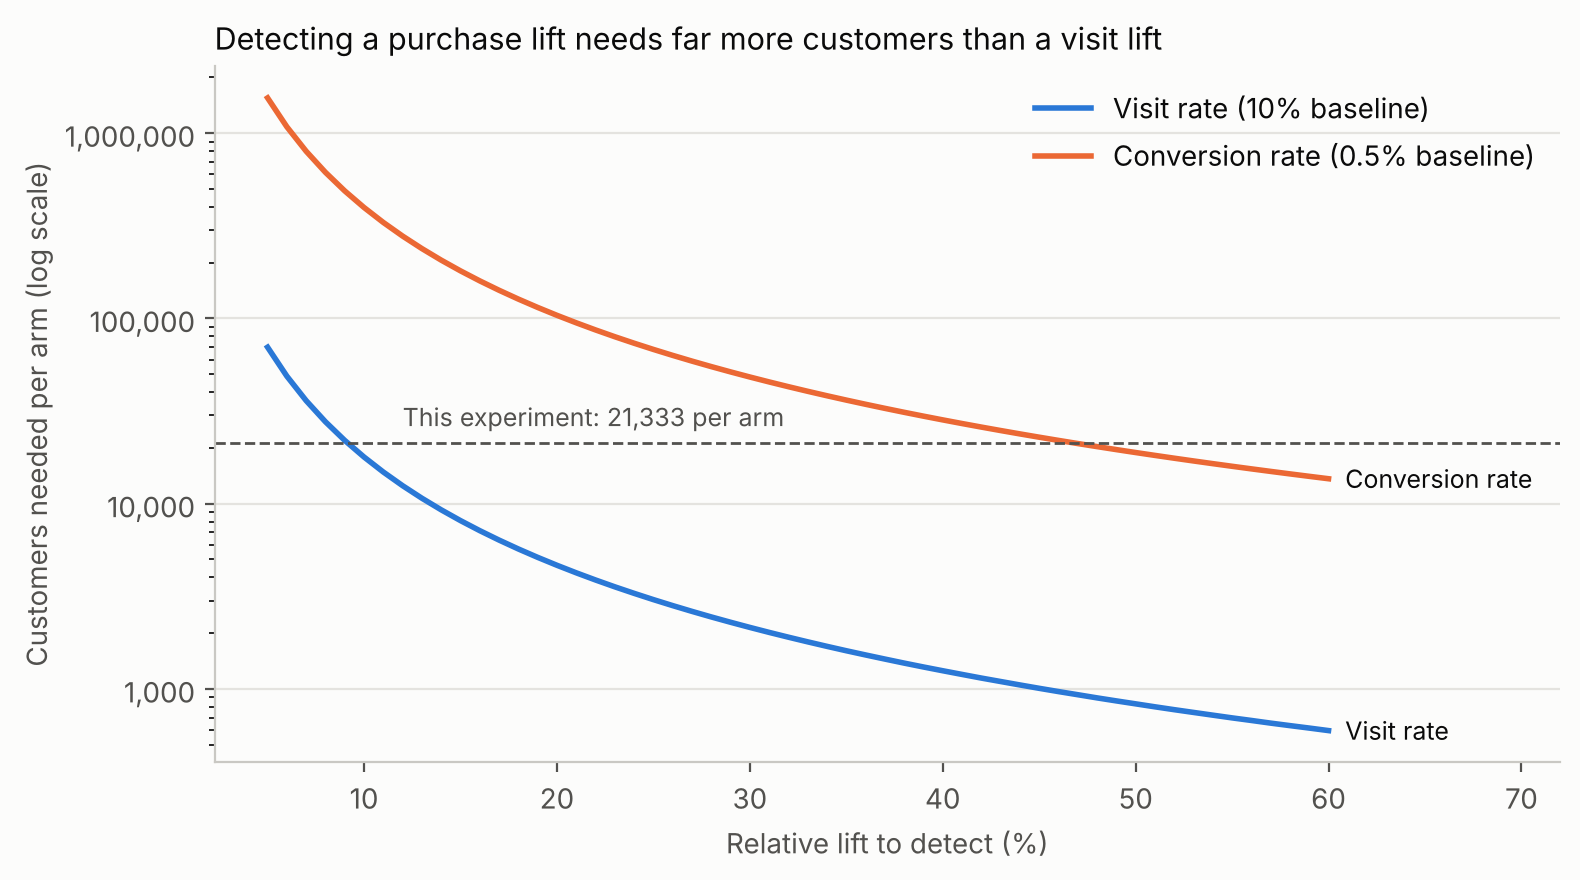

In [5]:
lifts = np.linspace(0.05, 0.60, 56)
needed = {
    name: [sample_size_proportions(base, base * (1 + lift), ALPHA, POWER)[0] for lift in lifts]
    for name, base in [
        ("Visit rate (10% baseline)", assumptions["visit_rate"]),
        ("Conversion rate (0.5% baseline)", assumptions["conversion_rate"]),
    ]
}

INK, INK_2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
COLORS = ["#2a78d6", "#eb6834"]  # validated categorical slots 1 and 2

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for (name, values), color in zip(needed.items(), COLORS):
    ax.plot(lifts * 100, values, color=color, linewidth=2, label=name)
    ax.annotate(name.split(" (")[0], xy=(lifts[-1] * 100, values[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK, fontsize=9)

ax.axhline(N_PER_ARM, color=INK_2, linewidth=1, linestyle="--")
ax.annotate(f"This experiment: {N_PER_ARM:,} per arm", xy=(12, N_PER_ARM),
            xytext=(0, 6), textcoords="offset points", color=INK_2, fontsize=9)

ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Relative lift to detect (%)", color=INK_2)
ax.set_ylabel("Customers needed per arm (log scale)", color=INK_2)
ax.set_title("Detecting a purchase lift needs far more customers than a visit lift",
             loc="left", color=INK, fontsize=11)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.tick_params(colors=INK_2)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#c9c8c3")
ax.legend(frameon=False, loc="upper right", labelcolor=INK)
ax.set_xlim(right=lifts[-1] * 100 + 12)
plt.tight_layout()
plt.show()

### Sensitivity to the conversion assumption

Our 0.5% baseline is a guess. How much does the conversion MDE depend on it?

In [6]:
rows = []
for base in [0.003, 0.005, 0.0075, 0.01, 0.015]:
    mde = mde_proportion(base, N_PER_ARM, N_PER_ARM, ALPHA, POWER)
    rows.append({"assumed baseline": base, "MDE (absolute)": mde, "MDE (relative)": mde / base})
pd.DataFrame(rows).style.format(
    {"assumed baseline": "{:.2%}", "MDE (absolute)": "{:.3%}", "MDE (relative)": "{:.0%}"}
).hide(axis="index")

assumed baseline,MDE (absolute),MDE (relative)
0.30%,0.187%,62%
0.50%,0.234%,47%
0.75%,0.280%,37%
1.00%,0.320%,32%
1.50%,0.385%,26%


The rarer the purchase, the larger the relative lift we need. If the true baseline is 1%, the experiment can detect about a 32% lift; if it is 0.3%, it needs more than 60%. Lesson 02 will tell us which world we are in, but the plan is fixed now.

## 9. Decision rules (written now, applied later)

1. **Validity first.** If the sample-ratio check gives p < 0.001, or pre-treatment covariates are clearly imbalanced, stop and investigate before reading any outcome.
2. **An email works** if its conversion lift over the holdout is positive and significant at family-wise α = 0.05 (Holm).
3. **Secondary metrics explain, they do not decide.** Visit and spend lifts are reported with 95% confidence intervals. If visits rise significantly but conversion does not, the conclusion is "the email brings traffic; a purchase effect was not shown", not "the email works".
4. **Choosing between emails.** Compare incremental spend per email sent, with a confidence interval. If the intervals overlap heavily, do not declare a winner; consider targeting instead (lesson 06).
5. **No new segments after the fact.** Any segment result not planned here is exploratory and would need a new test to confirm.
6. **Report the limitations.** No unsubscribe, complaint or margin data: we cannot rule out long-term costs of emailing.

## 10. Your turn

**a) Visit as the primary metric.** Suppose the marketing lead insists on visit rate. Rewrite decision rule 2. What business risk does that choice create?

**b) The cost of a holdout.** Every customer in the holdout is a customer you did not email. The retailer proposes keeping only 10% as holdout: 6,400 control and 28,800 per email. Use `mde_proportion(p_control, n_control, n_treatment, alpha, power)` to recompute the conversion MDE. How much detection power does the smaller holdout cost?

**c) A different baseline.** A colleague says last year's campaigns had a 1% two-week conversion rate without email. Update `assumptions` and rerun sections 7 and 8. Does that change your choice of primary metric?

In [7]:
# b) Your code here, for example:
# mde_small_holdout = mde_proportion(assumptions["conversion_rate"], 6_400, 28_800, ALPHA, POWER)
# print(f"{mde_small_holdout:.4f} absolute, {mde_small_holdout / assumptions['conversion_rate']:.0%} relative")

## Summary

The plan is fixed in `reports/pre_registration.md`: conversion as the primary metric, two confirmatory comparisons with Holm correction, and decision rules written before any outcome is seen. The power analysis says the experiment can detect a ~9% visit lift, a ~47% conversion lift and a ~57% spend lift under our assumptions.

**Next, lesson 02:** check that the randomisation worked and the data can be trusted, still without looking at outcomes.